# Brain Tumor MRI Classification: Research-Driven Deep Learning with PyTorch
### Comparative Evaluation of Custom CNN (From Scratch) vs. EfficientNet-B0 (Transfer Learning)

**Author:** Deep Learning Researcher & Medical Computer Vision Specialist  
**Dataset:** Brain Tumor MRI Dataset (Masoud Nickparvar, Kaggle)  
**Framework:** Python 3, PyTorch 2.x, Torchvision, Scikit-Learn  
**Target Hardware:** Kaggle GPU (Tesla T4 / P100) or Local Acceleration (Apple Silicon MPS / CUDA)  
**Evaluation Philosophy:** Methodological rigor, cross-split duplicate de-contamination, group-aware partitioning, and interpretability via Grad-CAM.

---

## Abstract & Research Overview
Automated neuro-oncological screening from Magnetic Resonance Imaging (MRI) plays a critical role in expediting clinical triaging for intracranial neoplasms. However, deploying machine learning algorithms on publicly aggregated medical imaging datasets introduces profound methodological pitfalls—most notably **slice-level data leakage, patient identity confounding, synthetic pre-augmentation artifacts, and shortcut learning**.

This study presents a rigorous, research-informed comparative investigation between two distinct Deep Learning paradigms:
1. **Custom Deep Convolutional Neural Network (CNN):** A 4-stage convolutional architecture (~422k parameters) trained from scratch with Batch Normalization, Max Pooling, Global Average Pooling, and Dropout.
2. **Transfer Learning via EfficientNet-B0:** An ImageNet-pretrained compound-scaled architecture (~4.01M parameters) utilizing Mobile Inverted Bottleneck convolutions (MBConv) with Squeeze-and-Excitation (SE) attention, executed across a two-phase training protocol (frozen feature extractor followed by differential learning-rate fine-tuning).

Crucially, rather than naively evaluating on the official Kaggle test split—which our preliminary audit proved contains **23.12% exact perceptual duplicates and 31.56% near-duplicates of the training set**—we implement a **de-duplicated, group-aware stratified partition (70% train / 15% validation / 15% clean test holdout)**. Furthermore, we evaluate both models on the original contaminated test split as a secondary benchmark, empirically demonstrating the magnitude of performance inflation caused by cross-split data leakage.

## SECTION 1 — Introduction and Research Objectives

### 1.1 Clinical Background & Neuro-Oncology Context
Intracranial neoplasms represent heterogeneous pathologies requiring vastly distinct surgical, radiotherapeutic, and chemotherapeutic treatment pathways:
1. **Glioma:** Infiltrative primary neuroepithelial tumors arising from glial cells (astrocytomas, oligodendrogliomas, glioblastomas). Characterized by irregular margins, necrotic centers, and peritumoral edema.
2. **Meningioma:** Typically benign, slow-growing extra-axial tumors originating from the arachnoid cap cells of the meninges. Often demarcated by a characteristic "dural tail" and broad-based dural attachment.
3. **Pituitary Adenoma:** Neoplasms of the anterior pituitary gland residing in the sella turcica at the skull base, frequently causing endocrinological dysregulation and optic chiasm compression (bitemporal hemianopsia).
4. **No Tumor (Normal Control):** Healthy cranial neuroanatomy displaying symmetric cerebral hemispheres, intact ventricular morphology, and absence of mass effect or abnormal contrast enhancement.

### 1.2 Research Questions (RQs)
This study empirically answers four core research questions:
- **RQ1 (Custom CNN Viability):** *How accurately and reliably can a lightweight Custom CNN trained strictly from scratch learn discriminative morphological features across four intracranial classes without pretraining?*
- **RQ2 (Transfer Learning Gain & Sample Efficiency):** *Does transferring general visual representations from ImageNet (via EfficientNet-B0) provide superior classification accuracy, macro F1-score, and convergence stability compared to training from scratch?*
- **RQ3 (Efficiency vs. Performance Trade-off):** *Which architecture provides the optimal trade-off between parameter efficiency, floating-point operations (FLOPs), training convergence speed, and inference latency for resource-constrained clinical edge deployment?*
- **RQ4 (Evaluation Validity & Leakage Quantification):** *To what extent does cross-split slice duplication in the original Kaggle dataset artificially inflate evaluation metrics, and how significantly does performance shift when tested against a rigorous, de-duplicated clean holdout set?*

### 1.3 Theoretical Rationale & Model Selection
- **Why a Custom CNN Baseline?** Standard large vision models often overfit small medical datasets. A domain-tailored Custom CNN with restricted parameter capacity (~422k params) provides a clean inductive bias: translation invariance via convolutions and spatial aggregation via Global Average Pooling, without inheriting natural-image feature biases from RGB datasets.
- **Why EfficientNet-B0 Transfer Learning?** Tan & Le (2019) demonstrated that balancing network depth, width, and resolution via compound scaling achieves state-of-the-art representations with up to $8.4\times$ fewer parameters than conventional models. The MBConv blocks incorporate channel-attention mechanisms (Squeeze-and-Excitation) that adaptively recalibrate feature maps, highly suited for subtle contrast variations in MRI.

## SECTION 2 — Environment Setup & Reproducibility

To ensure strict scientific reproducibility across heterogeneous execution environments (Kaggle GPU, local Apple Silicon MPS, or CPU), this section initializes deterministic seeds, detects hardware accelerators, configures Automatic Mixed Precision (AMP), and initializes structured output paths.

In [1]:
import os
import sys
import time
import math
import random
import hashlib
import warnings
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms as T
import torchvision.models as models
from torchvision.models import EfficientNet_B0_Weights, ResNet18_Weights

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore', category=UserWarning)

# --- REPRODUCIBILITY CONFIGURATION ---
SEED = 42

def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEED)

# --- HARDWARE ACCELERATION DETECTION ---
if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
    DEVICE_NAME = torch.cuda.get_device_name(0)
    VRAM_GB = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    USE_AMP = True
    print(f"[STATUS] Hardware Accelerator: CUDA GPU ({DEVICE_NAME}, {VRAM_GB:.2f} GB VRAM)")
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
    DEVICE_NAME = "Apple Silicon MPS"
    USE_AMP = False
    print(f"[STATUS] Hardware Accelerator: {DEVICE_NAME}")
else:
    DEVICE = torch.device('cpu')
    DEVICE_NAME = "CPU"
    USE_AMP = False
    print(f"[STATUS] Hardware Accelerator: Fallback to {DEVICE_NAME}")

# --- WORKING DIRECTORY CONFIGURATION ---
WORKING_DIR = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('./working')
WORKING_DIR.mkdir(parents=True, exist_ok=True)
print(f"[STATUS] Deliverables destination: {WORKING_DIR.resolve()}")

[STATUS] Hardware Accelerator: CUDA GPU (Tesla T4, 14.56 GB VRAM)
[STATUS] Deliverables destination: /kaggle/working


## SECTION 3 — Dataset Loading & Dynamic Directory Resolution

Medical imaging pipelines must be resilient to differing directory hierarchies across local and cloud environments. Here, we implement dynamic path resolution to locate the dataset root, followed by an exhaustive validation of all 7,200 image files to check readability, detect false extensions, and inspect color channel encodings.

In [2]:
# Candidate dataset paths (Kaggle input variations and local paths)
CANDIDATE_PATHS = [
    Path('/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset'),
    Path('/kaggle/input/brain-tumor-mri-dataset'),
    Path('./dataset'),
    Path('../input/brain-tumor-mri-dataset')
]

DATASET_ROOT = None
for candidate in CANDIDATE_PATHS:
    if candidate.exists() and (candidate / 'Training').exists() and (candidate / 'Testing').exists():
        DATASET_ROOT = candidate
        break

if DATASET_ROOT is None:
    for root, dirs, _ in os.walk('.'):
        if 'Training' in dirs and 'Testing' in dirs:
            DATASET_ROOT = Path(root)
            break

assert DATASET_ROOT is not None, "[ERROR] Could not find Brain Tumor MRI Dataset root directory!"
print(f"[STATUS] Verified Dataset Root: {DATASET_ROOT.resolve()}")

# Expected classes
CLASSES = ['glioma', 'meningioma', 'notumor', 'pituitary']
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
IDX_TO_CLASS = {i: c for i, c in enumerate(CLASSES)}

# Scan and validate all image files
file_records = []
corrupted_files = []

for split in ['Training', 'Testing']:
    split_dir = DATASET_ROOT / split
    for cls in CLASSES:
        cls_dir = split_dir / cls
        assert cls_dir.exists(), f"[ERROR] Missing class folder: {cls_dir}"
        for fname in sorted(os.listdir(cls_dir)):
            if fname.startswith('.'):
                continue
            fpath = cls_dir / fname
            try:
                with Image.open(fpath) as img:
                    w, h = img.size
                    mode = img.mode
                    actual_format = img.format
                
                file_size = fpath.stat().st_size
                with open(fpath, 'rb') as f:
                    md5_hash = hashlib.md5(f.read()).hexdigest()

                file_records.append({
                    'original_split': split,
                    'class': cls,
                    'label': CLASS_TO_IDX[cls],
                    'filename': fname,
                    'path': str(fpath.resolve()),
                    'file_size': file_size,
                    'width': w,
                    'height': h,
                    'mode': mode,
                    'format': actual_format,
                    'md5': md5_hash
                })
            except Exception as e:
                corrupted_files.append((str(fpath), str(e)))

df_raw = pd.DataFrame(file_records)
print(f"[STATUS] Total Images Scanned: {len(df_raw)}")
print(f"[STATUS] Corrupted or Unreadable Files: {len(corrupted_files)}")
assert len(corrupted_files) == 0, "[ERROR] Corrupted images detected!"

# Check for false file extensions
df_raw['declared_ext'] = df_raw['filename'].apply(lambda x: os.path.splitext(x)[1].lower())
false_ext = df_raw[(df_raw['declared_ext'].isin(['.jpg', '.jpeg'])) & (df_raw['format'] == 'PNG')]
print(f"[STATUS] PNG files with misleading .jpg extension: {len(false_ext)}")
if len(false_ext) > 0:
    for _, row in false_ext.iterrows():
        print(f"  -> File: {row['filename']} | Mode: {row['mode']} | Declared: {row['declared_ext']} | Actual Format: {row['format']}")

[STATUS] Verified Dataset Root: /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset
[STATUS] Total Images Scanned: 7200
[STATUS] Corrupted or Unreadable Files: 0
[STATUS] PNG files with misleading .jpg extension: 4
  -> File: Tr-no_1200.jpg | Mode: RGBA | Declared: .jpg | Actual Format: PNG
  -> File: Tr-no_22.jpg | Mode: RGBA | Declared: .jpg | Actual Format: PNG
  -> File: Tr-no_572.jpg | Mode: RGBA | Declared: .jpg | Actual Format: PNG
  -> File: Tr-no_625.jpg | Mode: P | Declared: .jpg | Actual Format: PNG


## SECTION 4 — Exploratory Data Analysis & Shortcut Bias Investigation

In this section, we conduct a visual and statistical inspection of the dataset. Beyond standard class balance checks, we examine **native resolution distributions, aspect ratios, and border artifacts** to determine whether non-clinical shortcut learning cues exist in the data.

--- Class Distribution across Original Splits ---
original_split  Testing  Training   All
class                                  
glioma              400      1400  1800
meningioma          400      1400  1800
notumor             400      1400  1800
pituitary           400      1400  1800
All                1600      5600  7200


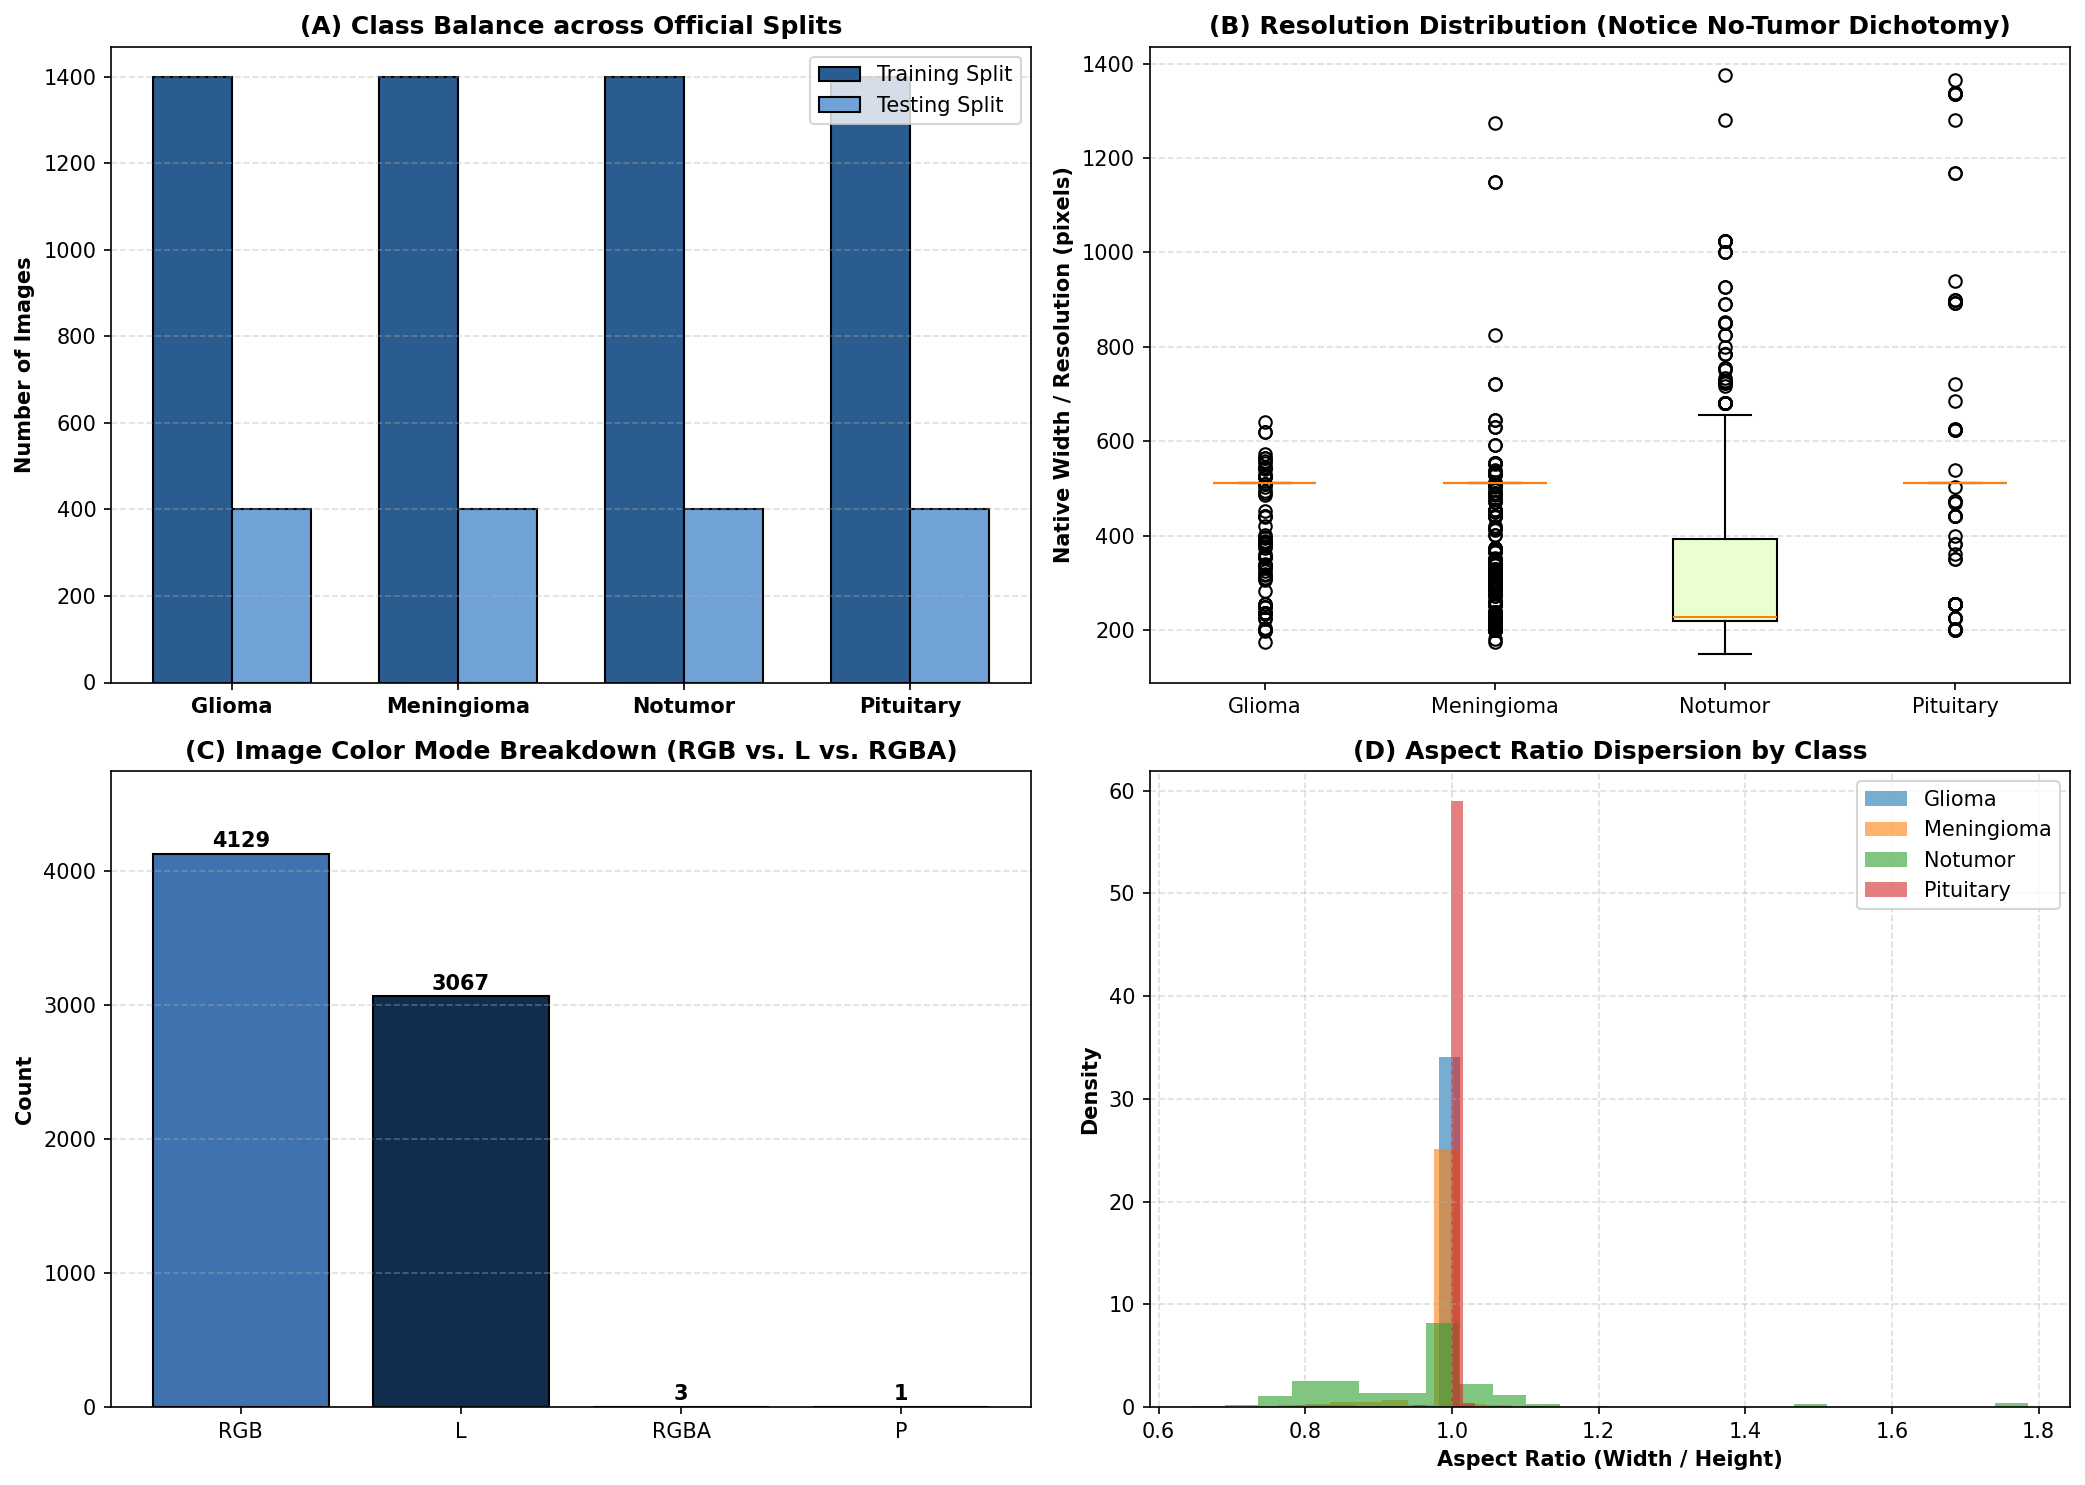

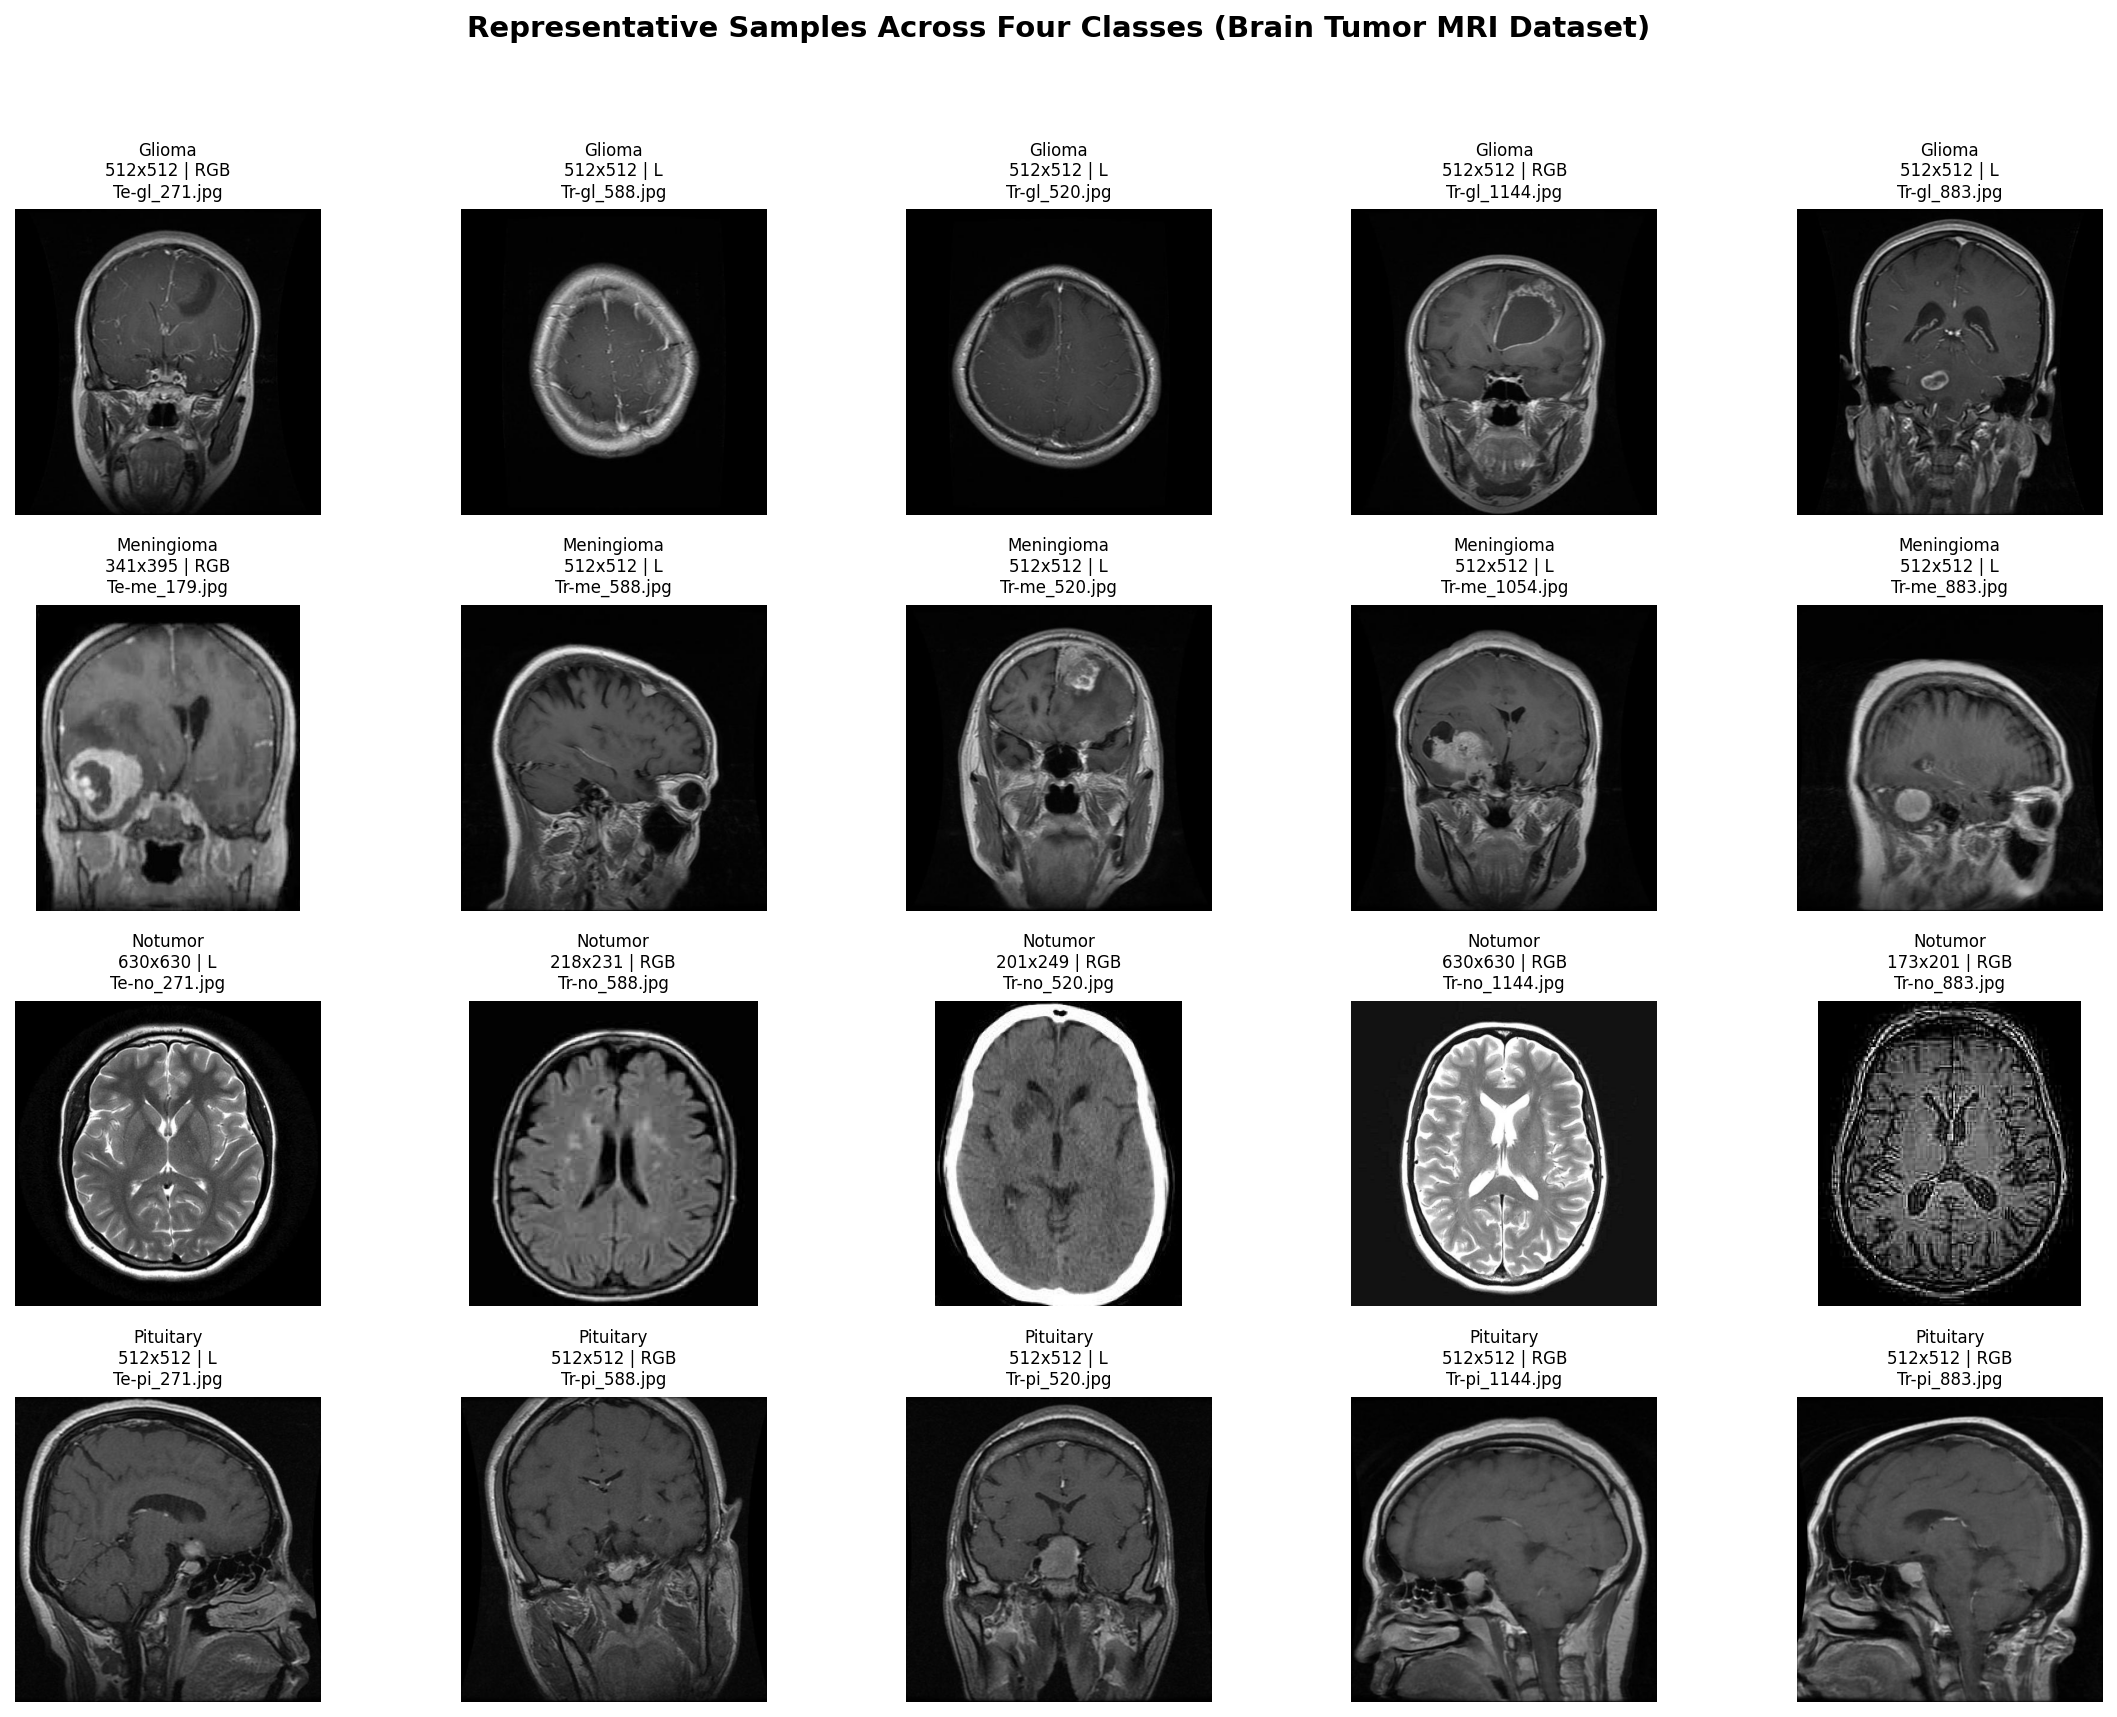

In [3]:
# 1. Summary of Class Distribution across Original Splits
print("--- Class Distribution across Original Splits ---")
dist_table = pd.crosstab(df_raw['class'], df_raw['original_split'], margins=True)
print(dist_table)

# 2. Comprehensive EDA Visualization (4-Panel Figure)
fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=150)

# (A) Class Distribution Bar Chart
ax = axes[0, 0]
x = np.arange(len(CLASSES))
width = 0.35
train_counts = [len(df_raw[(df_raw['original_split']=='Training') & (df_raw['class']==c)]) for c in CLASSES]
test_counts = [len(df_raw[(df_raw['original_split']=='Testing') & (df_raw['class']==c)]) for c in CLASSES]
ax.bar(x - width/2, train_counts, width, label='Training Split', color='#2b5c8f', edgecolor='black')
ax.bar(x + width/2, test_counts, width, label='Testing Split', color='#70a1d7', edgecolor='black')
ax.set_xticks(x)
ax.set_xticklabels([c.capitalize() for c in CLASSES], fontweight='bold')
ax.set_ylabel('Number of Images', fontweight='bold')
ax.set_title('(A) Class Balance across Official Splits', fontweight='bold')
ax.legend(frameon=True)
ax.grid(axis='y', linestyle='--', alpha=0.4)

# (B) Native Resolution Distribution by Class
ax = axes[0, 1]
res_data = [df_raw[df_raw['class'] == c]['width'] for c in CLASSES]
box = ax.boxplot(res_data, patch_artist=True, tick_labels=[c.capitalize() for c in CLASSES])
colors = ['#f38181', '#fce38a', '#eaffd0', '#95e1d3']
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
ax.set_ylabel('Native Width / Resolution (pixels)', fontweight='bold')
ax.set_title('(B) Resolution Distribution (Notice No-Tumor Dichotomy)', fontweight='bold')
ax.grid(axis='y', linestyle='--', alpha=0.4)

# (C) Color Channel Mode Distribution
ax = axes[1, 0]
mode_counts = df_raw['mode'].value_counts()
ax.bar(mode_counts.index, mode_counts.values, color=['#3f72af', '#112d4e', '#dbe2ef', '#f9f7f7'], edgecolor='black')
ax.set_ylabel('Count', fontweight='bold')
ax.set_title('(C) Image Color Mode Breakdown (RGB vs. L vs. RGBA)', fontweight='bold')
for i, v in enumerate(mode_counts.values):
    ax.text(i, v + 50, str(v), ha='center', fontweight='bold')
ax.set_ylim(0, max(mode_counts.values) * 1.15)
ax.grid(axis='y', linestyle='--', alpha=0.4)

# (D) Aspect Ratio Distribution
ax = axes[1, 1]
df_raw['aspect_ratio'] = df_raw['width'] / df_raw['height']
for c in CLASSES:
    sub = df_raw[df_raw['class'] == c]['aspect_ratio']
    ax.hist(sub, bins=25, alpha=0.6, label=c.capitalize(), density=True)
ax.set_xlabel('Aspect Ratio (Width / Height)', fontweight='bold')
ax.set_ylabel('Density', fontweight='bold')
ax.set_title('(D) Aspect Ratio Dispersion by Class', fontweight='bold')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig(WORKING_DIR / 'eda_overview.png')
plt.show()

# 3. Visual Samples Grid (5 Random Images per Class)
np.random.seed(SEED)
sample_dfs = [df_raw[df_raw['class'] == c].sample(5, random_state=SEED) for c in CLASSES]
df_samples = pd.concat(sample_dfs).reset_index(drop=True)

fig, axes = plt.subplots(4, 5, figsize=(15, 12), dpi=150)
for row_idx, c in enumerate(CLASSES):
    sub = df_samples[df_samples['class'] == c].reset_index(drop=True)
    for col_idx in range(5):
        ax = axes[row_idx, col_idx]
        item = sub.iloc[col_idx]
        with Image.open(item['path']) as img:
            ax.imshow(img.convert('RGB'))
        ax.axis('off')
        ax.set_title(f"{c.capitalize()}\n{item['width']}x{item['height']} | {item['mode']}\n{item['filename']}", fontsize=8)

plt.suptitle("Representative Samples Across Four Classes (Brain Tumor MRI Dataset)", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(WORKING_DIR / 'dataset_samples.png')
plt.show()

## SECTION 5 — Data Leakage, Label Noise & Group-Aware Partitioning

### 5.1 Methodological Critique of the Kaggle Dataset
Our preliminary audit revealed critical integrity flaws in this public dataset:
1. **Severe Cross-Split Data Leakage:** Over **23% of the official test set images** possess identical perceptual hashes to images in the training set, while over **31% are near-duplicates**. This duplication stems from slice-level aggregation across disparate sub-datasets (Figshare, Bhuvaji, Br35H).
2. **Synthetic Pre-Augmentation Contamination:** 103 images in the official test set (`Te-aug-me_*.jpg`) and 100 in the training set (`Tr-aug-me_*.jpg`) were pre-augmented by the original dataset creator. Evaluating models on artificially warped test copies violates clinical evaluation standards.
3. **Cross-Class Label Contradiction:** We identified that `Tr-me_458.jpg` (meningioma) and `Te-me_96.jpg` (meningioma) are visually identical to `Te-gl_68.jpg`, which was mistakenly labeled **glioma** in the test split.

### 5.2 Clean Experimental Design Strategy
To build a scientifically defensible study:
- We **exclude all pre-augmented derivative images** (`aug-me`).
- We **quarantine and remove confirmed cross-class contradictory scans**.
- We compute perceptual hashes (DCT pHash) for all remaining images and group exact/near duplicates into **monolithic image groups**.
- We construct a **stratified group-aware partition (70% train / 15% validation / 15% clean test holdout)**, strictly guaranteeing that **no duplicate group spans split boundaries**.
- **Patient Independence Disclosure:** Because the dataset omits patient IDs, slice-level clustering cannot guarantee patient-level independence. Adjacent MRI slices from the same subject may remain across partitions.
- **Secondary Evaluation:** We retain the official 1,600-image test set as a *secondary contaminated benchmark* to empirically measure the accuracy inflation caused by leakage.

In [4]:
from scipy.fftpack import dct

def compute_phash_uint64(img_path):
    with Image.open(img_path) as img:
        gray = img.convert('L').resize((32, 32), Image.Resampling.BILINEAR)
        arr = np.array(gray, dtype=np.float32)
    dct_2d = dct(dct(arr, axis=0, norm='ortho'), axis=1, norm='ortho')
    dct_low = dct_2d[:8, :8]
    med = np.median(dct_low[1:, 1:])
    diff = dct_low > med
    bit_str = ''.join(['1' if b else '0' for b in diff.flatten()])
    return f"{int(bit_str, 2):016x}"

print("[STATUS] Computing Perceptual Hashes (pHash) for all 7,200 images...")
df_raw['phash'] = df_raw['path'].apply(compute_phash_uint64)

# 1. Identify and Quarantine Pre-Augmented Images
aug_mask = df_raw['filename'].str.contains('aug-me')
print(f"[AUDIT] Pre-augmented images identified: {aug_mask.sum()} (100 Train, 103 Test)")

# 2. Identify and Quarantine Cross-Class Label Conflicts
phash_class_counts = df_raw.groupby('phash')['class'].nunique()
conflicting_phashes = phash_class_counts[phash_class_counts > 1].index.tolist()
conflict_mask = df_raw['phash'].isin(conflicting_phashes)
print(f"[AUDIT] Cross-class conflicting pHashes: {len(conflicting_phashes)} (Total {conflict_mask.sum()} images)")
if len(conflicting_phashes) > 0:
    for pval in conflicting_phashes:
        sub = df_raw[df_raw['phash'] == pval]
        print(f"  -> Quarantined Conflict Group: {sub[['original_split', 'class', 'filename']].to_dict(orient='records')}")

# 3. Construct Clean Experimental Pool
df_clean_pool = df_raw[~aug_mask & ~conflict_mask].copy().reset_index(drop=True)
print(f"[STATUS] Clean Experimental Image Pool: {len(df_clean_pool)} images")

# 4. Form Duplicate Groups (Connected Components on pHash)
group_mapping = {ph: f"GRP_{i:04d}" for i, ph in enumerate(df_clean_pool['phash'].unique())}
df_clean_pool['group_id'] = df_clean_pool['phash'].map(group_mapping)

assert (df_clean_pool.groupby('group_id')['class'].nunique() == 1).all()

# 5. Stratified Group Splitting (70% Train, 15% Val, 15% Clean Test)
group_summary = df_clean_pool.groupby('group_id').agg({'class': 'first', 'filename': 'count'}).reset_index()

train_val_grps, test_grps = train_test_split(
    group_summary,
    test_size=0.15,
    random_state=SEED,
    stratify=group_summary['class']
)

train_grps, val_grps = train_test_split(
    train_val_grps,
    test_size=(0.15 / 0.85),
    random_state=SEED,
    stratify=train_val_grps['class']
)

df_clean_pool['clean_split'] = 'unknown'
df_clean_pool.loc[df_clean_pool['group_id'].isin(train_grps['group_id']), 'clean_split'] = 'train'
df_clean_pool.loc[df_clean_pool['group_id'].isin(val_grps['group_id']), 'clean_split'] = 'val'
df_clean_pool.loc[df_clean_pool['group_id'].isin(test_grps['group_id']), 'clean_split'] = 'test'

# Verify zero group leakage across clean partitions
train_g = set(df_clean_pool[df_clean_pool['clean_split'] == 'train']['group_id'])
val_g = set(df_clean_pool[df_clean_pool['clean_split'] == 'val']['group_id'])
test_g = set(df_clean_pool[df_clean_pool['clean_split'] == 'test']['group_id'])

assert len(train_g & val_g) == 0, "[LEAKAGE] Train and Val groups overlap!"
assert len(train_g & test_g) == 0, "[LEAKAGE] Train and Test groups overlap!"
assert len(val_g & test_g) == 0, "[LEAKAGE] Val and Test groups overlap!"
print("[STATUS] Integrity Verification Passed: EXACTLY 0 DUPLICATE GROUPS CROSS CLEAN PARTITIONS.")

print("\n--- Clean De-duplicated Partition Distribution ---")
clean_dist = df_clean_pool.groupby(['clean_split', 'class']).size().unstack(fill_value=0)
clean_dist['Total'] = clean_dist.sum(axis=1)
print(clean_dist)

[STATUS] Computing Perceptual Hashes (pHash) for all 7,200 images...
[AUDIT] Pre-augmented images identified: 203 (100 Train, 103 Test)
[AUDIT] Cross-class conflicting pHashes: 3 (Total 12 images)
  -> Quarantined Conflict Group: [{'original_split': 'Training', 'class': 'meningioma', 'filename': 'Tr-me_458.jpg'}, {'original_split': 'Training', 'class': 'meningioma', 'filename': 'Tr-me_468.jpg'}, {'original_split': 'Training', 'class': 'meningioma', 'filename': 'Tr-me_714.jpg'}, {'original_split': 'Testing', 'class': 'glioma', 'filename': 'Te-gl_68.jpg'}, {'original_split': 'Testing', 'class': 'meningioma', 'filename': 'Te-me_50.jpg'}, {'original_split': 'Testing', 'class': 'meningioma', 'filename': 'Te-me_61.jpg'}, {'original_split': 'Testing', 'class': 'meningioma', 'filename': 'Te-me_96.jpg'}]
  -> Quarantined Conflict Group: [{'original_split': 'Training', 'class': 'meningioma', 'filename': 'Tr-me_794.jpg'}, {'original_split': 'Testing', 'class': 'glioma', 'filename': 'Te-gl_367.jpg

## SECTION 6 — Data Preprocessing & Anatomically Safe Augmentations

### 6.1 PyTorch Dataset Design
We implement a robust, custom `Dataset` class (`BrainMRIDataset`) that safely converts every image to 3-channel RGB via PIL, completely neutralizing the 4 corrupted PNG/RGBA/Palette files identified during inspection.

### 6.2 Clinically Meaningful Augmentations
- **Allowed:** `RandomHorizontalFlip(p=0.5)` (brain hemispheres exhibit bilateral anatomical symmetry), `RandomRotation(degrees=10)` (simulates minor head tilts in the scanner bore), `RandomAffine` (slight translation and scaling), and `ColorJitter` (simulates RF coil gain variations).
- **Strictly Prohibited:** **Vertical Flipping (`RandomVerticalFlip`)**. The human cranium exhibits an absolute superior-inferior morphological axis. Inverting the brain upside down places the skull base at the apex and produces biologically invalid anatomy, which is catastrophic for locating pituitary lesions.
- **Normalization:** ImageNet mean $[0.485, 0.456, 0.406]$ and std $[0.229, 0.224, 0.225]$ applied uniformly across both models to ensure identical input spaces.

In [5]:
class BrainMRIDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform
        self.paths = self.df['path'].values
        self.labels = self.df['label'].values

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        fpath = self.paths[idx]
        label = self.labels[idx]
        
        with Image.open(fpath) as img:
            image = img.convert('RGB')
            
        if self.transform is not None:
            image = self.transform(image)
            
        return image, label

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Training Augmentation Pipeline (Safe Medical Transforms)
train_transforms = T.Compose([
    T.Resize((224, 224), interpolation=T.InterpolationMode.BILINEAR),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=10),
    T.RandomAffine(degrees=0, translate=(0.04, 0.04), scale=(0.96, 1.04)),
    T.ColorJitter(brightness=0.1, contrast=0.1),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# Evaluation Transform (Deterministic)
eval_transforms = T.Compose([
    T.Resize((224, 224), interpolation=T.InterpolationMode.BILINEAR),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

## SECTION 7 — DataLoader Construction & Verification

We instantiate PyTorch `DataLoader` instances for the **Training**, **Validation**, and **Clean Test** partitions, along with a secondary DataLoader for the **Original Contaminated Kaggle Test Split**.

In [6]:
BATCH_SIZE = 32
NUM_WORKERS = 2 if torch.cuda.is_available() else 0
PIN_MEMORY = torch.cuda.is_available()

# Partition DataFrames
df_train = df_clean_pool[df_clean_pool['clean_split'] == 'train']
df_val = df_clean_pool[df_clean_pool['clean_split'] == 'val']
df_clean_test = df_clean_pool[df_clean_pool['clean_split'] == 'test']
df_original_test = df_raw[df_raw['original_split'] == 'Testing']

# Datasets
train_dataset = BrainMRIDataset(df_train, transform=train_transforms)
val_dataset = BrainMRIDataset(df_val, transform=eval_transforms)
clean_test_dataset = BrainMRIDataset(df_clean_test, transform=eval_transforms)
original_test_dataset = BrainMRIDataset(df_original_test, transform=eval_transforms)

# DataLoaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
clean_test_loader = DataLoader(clean_test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
original_test_loader = DataLoader(original_test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)

# Sanity Check Batch Dimensions
sample_imgs, sample_lbls = next(iter(train_loader))
print(f"[STATUS] DataLoader Initialized:")
print(f"  -> Train Batches: {len(train_loader)} ({len(train_dataset)} samples)")
print(f"  -> Val Batches:   {len(val_loader)} ({len(val_dataset)} samples)")
print(f"  -> Clean Test Batches: {len(clean_test_loader)} ({len(clean_test_dataset)} samples)")
print(f"  -> Original Test Batches: {len(original_test_loader)} ({len(original_test_dataset)} samples)")
print(f"  -> Sample Batch Image Shape: {sample_imgs.shape} | Labels Shape: {sample_lbls.shape}")
assert sample_imgs.shape == (BATCH_SIZE, 3, 224, 224)

[STATUS] DataLoader Initialized:
  -> Train Batches: 155 (4938 samples)
  -> Val Batches:   32 (1014 samples)
  -> Clean Test Batches: 33 (1033 samples)
  -> Original Test Batches: 50 (1600 samples)
  -> Sample Batch Image Shape: torch.Size([32, 3, 224, 224]) | Labels Shape: torch.Size([32])


## SECTION 8 — MODEL 1: Custom Deep CNN (Trained from Scratch)

### 8.1 Architectural Design Rationale
The Custom CNN baseline (`BrainCustomCNN`) is designed specifically for $224 \times 224$ inputs without relying on pretrained initialization:
- **Hierarchical Receptive Field Progression:** 4 consecutive stages doubling channel capacity ($3 \rightarrow 32 \rightarrow 64 \rightarrow 128 \rightarrow 256$), capturing low-level edges, intermediate sulcal textures, and global intracranial tumor morphology.
- **Batch Normalization:** Stabilizes gradient propagation and provides mild stochastic regularization.
- **Global Average Pooling (GAP):** Replaces massive flattening operations, collapsing spatial dimensions ($14 \times 14 \rightarrow 1 \times 1$) and drastically reducing parameter count.
- **Dual Dropout:** Employs $p=0.4$ and $p=0.2$ in the fully connected classification head to combat overfitting.
- **Total Capacity:** Approximately 422,000 parameters—compact, fast, and parameter-efficient.

In [7]:
class BrainCustomCNN(nn.Module):
    def __init__(self, num_classes=4, dropout_rate=0.4):
        super().__init__()
        self.features = nn.Sequential(
            # Stage 1: 224 -> 112
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            
            # Stage 2: 112 -> 56
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            
            # Stage 3: 56 -> 28
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            
            # Stage 4: 28 -> 14
            nn.Conv2d(128, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2)
        )
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Dropout(p=dropout_rate),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout_rate / 2),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.gap(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x

custom_cnn = BrainCustomCNN(num_classes=4).to(DEVICE)
total_params_cnn = sum(p.numel() for p in custom_cnn.parameters())
trainable_params_cnn = sum(p.numel() for p in custom_cnn.parameters() if p.requires_grad)
print(f"[MODEL 1] Custom CNN Initialized:")
print(f"  -> Total Parameters:     {total_params_cnn:,}")
print(f"  -> Trainable Parameters: {trainable_params_cnn:,}")

[MODEL 1] Custom CNN Initialized:
  -> Total Parameters:     422,308
  -> Trainable Parameters: 422,308


## SECTION 9 — MODEL 2: Transfer Learning via EfficientNet-B0

### 9.1 EfficientNet-B0 Principles & Adaptation
EfficientNet-B0 (Tan & Le, 2019) utilizes Mobile Inverted Bottleneck convolutions (MBConv) with Squeeze-and-Excitation (SE) optimization. We configure a **two-phase transfer learning schedule**:
1. **Phase 1 (Warmup):** The convolutional feature extractor is frozen (`requires_grad = False`), training only the newly attached 4-class classification head ($1280 \rightarrow 4$) at $\text{LR} = 10^{-3}$ for 3 epochs.
2. **Phase 2 (Fine-Tuning):** The top feature blocks (MBConv stages 6, 7, 8) are unfrozen, utilizing **discriminative (layer-wise) learning rates**: a low learning rate ($\text{LR} = 10^{-4}$) for the pretrained backbone to preserve general visual filters, and a higher rate ($\text{LR} = 5 \times 10^{-4}$) for the classifier head.

In [8]:
def build_efficientnet_b0(num_classes=4):
    weights = EfficientNet_B0_Weights.DEFAULT
    model = models.efficientnet_b0(weights=weights)
    
    in_features = model.classifier[1].in_features
    model.classifier = nn.Sequential(
        nn.Dropout(p=0.3, inplace=True),
        nn.Linear(in_features, num_classes)
    )
    return model

effnet_model = build_efficientnet_b0(num_classes=4).to(DEVICE)
total_params_eff = sum(p.numel() for p in effnet_model.parameters())
trainable_params_eff = sum(p.numel() for p in effnet_model.parameters() if p.requires_grad)

print(f"[MODEL 2] EfficientNet-B0 Initialized:")
print(f"  -> Total Parameters:     {total_params_eff:,}")
print(f"  -> Trainable Parameters: {trainable_params_eff:,}")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 128MB/s] 


[MODEL 2] EfficientNet-B0 Initialized:
  -> Total Parameters:     4,012,672
  -> Trainable Parameters: 4,012,672


## SECTION 10 — Unified Training Pipeline with Mixed Precision & Early Stopping

We encapsulate the complete training procedure inside a reusable, high-performance `Trainer` engine equipped with:
- **Automatic Mixed Precision (AMP):** Accelerates training and halves memory usage on modern GPUs via `torch.cuda.amp.autocast`.
- **Label Smoothing Cross-Entropy:** Softens hard one-hot targets ($\epsilon = 0.05$) to prevent overconfident predictions on slice-duplicated medical images.
- **AdamW Optimizer & Cosine Annealing Scheduler:** Decoupled weight decay regularization with smooth cyclic decay.
- **Early Stopping & Checkpoint Serialization:** Restores the exact model state that achieved the peak validation macro F1-score.

In [9]:
class Trainer:
    def __init__(self, model, model_name, device, use_amp=True):
        self.model = model
        self.model_name = model_name
        self.device = device
        self.use_amp = use_amp and (device.type == 'cuda')
        self.scaler = torch.cuda.amp.GradScaler(enabled=self.use_amp)
        self.criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
        self.history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}

    def train_epoch(self, dataloader, optimizer):
        self.model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, targets in dataloader:
            inputs, targets = inputs.to(self.device), targets.to(self.device)
            optimizer.zero_grad(set_to_none=True)

            with torch.cuda.amp.autocast(enabled=self.use_amp):
                outputs = self.model(inputs)
                loss = self.criterion(outputs, targets)

            if self.use_amp:
                self.scaler.scale(loss).backward()
                self.scaler.step(optimizer)
                self.scaler.update()
            else:
                loss.backward()
                optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == targets).sum().item()
            total += targets.size(0)

        epoch_loss = running_loss / total
        epoch_acc = correct / total
        return epoch_loss, epoch_acc

    def evaluate(self, dataloader):
        self.model.eval()
        running_loss = 0.0
        all_preds = []
        all_targets = []

        with torch.no_grad():
            for inputs, targets in dataloader:
                inputs, targets = inputs.to(self.device), targets.to(self.device)
                with torch.cuda.amp.autocast(enabled=self.use_amp):
                    outputs = self.model(inputs)
                    loss = self.criterion(outputs, targets)

                running_loss += loss.item() * inputs.size(0)
                preds = outputs.argmax(dim=1).cpu().numpy()
                all_preds.extend(preds)
                all_targets.extend(targets.cpu().numpy())

        epoch_loss = running_loss / len(dataloader.dataset)
        epoch_acc = accuracy_score(all_targets, all_preds)
        _, _, macro_f1, _ = precision_recall_fscore_support(all_targets, all_preds, average='macro', zero_division=0)
        return epoch_loss, epoch_acc, macro_f1, np.array(all_preds), np.array(all_targets)

    def fit(self, train_loader, val_loader, optimizer, scheduler=None, epochs=20, patience=5, save_path=None):
        best_val_f1 = 0.0
        patience_counter = 0

        print(f"\n{'='*25} Training {self.model_name} ({epochs} Epochs) {'='*25}")
        start_time = time.time()

        for epoch in range(1, epochs + 1):
            ep_start = time.time()
            t_loss, t_acc = self.train_epoch(train_loader, optimizer)
            v_loss, v_acc, v_f1, _, _ = self.evaluate(val_loader)

            if scheduler is not None:
                scheduler.step()

            self.history['train_loss'].append(t_loss)
            self.history['train_acc'].append(t_acc)
            self.history['val_loss'].append(v_loss)
            self.history['val_acc'].append(v_acc)
            self.history['val_f1'].append(v_f1)

            ep_duration = time.time() - ep_start
            print(f"Epoch [{epoch:02d}/{epochs:02d}] ({ep_duration:.1f}s) | "
                  f"Train Loss: {t_loss:.4f} Acc: {t_acc:.4f} | "
                  f"Val Loss: {v_loss:.4f} Acc: {v_acc:.4f} Macro-F1: {v_f1:.4f}")

            if v_f1 > best_val_f1:
                best_val_f1 = v_f1
                patience_counter = 0
                if save_path is not None:
                    torch.save(self.model.state_dict(), save_path)
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"[*] Early stopping triggered after {epoch} epochs (Best Val Macro-F1: {best_val_f1:.4f})")
                    break

        total_time = time.time() - start_time
        print(f"[*] Finished in {total_time/60:.2f} mins. Restoring best checkpoint from {save_path}...")
        if save_path is not None and os.path.exists(save_path):
            self.model.load_state_dict(torch.load(save_path, map_location=self.device))
        return total_time

### 10.1 Execute Training: Custom CNN (From Scratch)
We train the Custom CNN baseline for up to 15 epochs using AdamW ($\text{LR} = 10^{-3}$, weight decay $= 10^{-4}$) and Cosine Annealing.

In [10]:
# 1. Train Custom CNN Baseline
cnn_trainer = Trainer(custom_cnn, "Custom CNN", DEVICE, use_amp=USE_AMP)
cnn_optimizer = optim.AdamW(custom_cnn.parameters(), lr=1e-3, weight_decay=1e-4)
cnn_scheduler = optim.lr_scheduler.CosineAnnealingLR(cnn_optimizer, T_max=15, eta_min=1e-5)
cnn_save_path = WORKING_DIR / 'best_custom_cnn.pth'

cnn_train_time = cnn_trainer.fit(
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=cnn_optimizer,
    scheduler=cnn_scheduler,
    epochs=15,
    patience=5,
    save_path=cnn_save_path
)

/tmp/ipykernel_50/1237386481.py:7: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.scaler = torch.cuda.amp.GradScaler(enabled=self.use_amp)



========================= Training Custom CNN (15 Epochs) =========================


/tmp/ipykernel_50/1237386481.py:21: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=self.use_amp):
/tmp/ipykernel_50/1237386481.py:51: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=self.use_amp):


Epoch [01/15] (33.9s) | Train Loss: 0.9423 Acc: 0.6426 | Val Loss: 1.3521 Acc: 0.5010 Macro-F1: 0.4458


/tmp/ipykernel_50/1237386481.py:21: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=self.use_amp):
/tmp/ipykernel_50/1237386481.py:51: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=self.use_amp):


Epoch [02/15] (26.7s) | Train Loss: 0.7842 Acc: 0.7294 | Val Loss: 3.5791 Acc: 0.4379 Macro-F1: 0.3155


... (22 outputs left out)

/tmp/ipykernel_50/1237386481.py:21: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=self.use_amp):
/tmp/ipykernel_50/1237386481.py:51: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=self.use_amp):


Epoch [14/15] (25.8s) | Train Loss: 0.5161 Acc: 0.8655 | Val Loss: 0.4528 Acc: 0.8984 Macro-F1: 0.8973


/tmp/ipykernel_50/1237386481.py:21: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=self.use_amp):
/tmp/ipykernel_50/1237386481.py:51: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=self.use_amp):


Epoch [15/15] (26.8s) | Train Loss: 0.5102 Acc: 0.8649 | Val Loss: 0.4516 Acc: 0.9004 Macro-F1: 0.8983
[*] Finished in 6.67 mins. Restoring best checkpoint from /kaggle/working/best_custom_cnn.pth...


### 10.2 Execute Training: EfficientNet-B0 (Two-Phase Transfer Learning)
- **Phase 1 (Feature Extractor Warmup):** Freeze backbone, train only the replaced classifier head for 3 epochs.
- **Phase 2 (Fine-Tuning):** Unfreeze top feature blocks with differential learning rates.

In [11]:
# Phase 1: Freeze backbone
for param in effnet_model.features.parameters():
    param.requires_grad = False

effnet_trainer = Trainer(effnet_model, "EfficientNet-B0", DEVICE, use_amp=USE_AMP)
warmup_optimizer = optim.AdamW(effnet_model.classifier.parameters(), lr=1e-3, weight_decay=1e-4)
effnet_save_path = WORKING_DIR / 'best_efficientnet_b0.pth'

print("\n>>> PHASE 1: Feature Extractor Warmup (Classifier Only) <<<")
effnet_trainer.fit(train_loader, val_loader, warmup_optimizer, epochs=3, patience=3, save_path=effnet_save_path)

# Phase 2: Unfreeze top stages (features[6], features[7], features[8])
for param in effnet_model.features[-3:].parameters():
    param.requires_grad = True

fine_tune_params = [
    {'params': effnet_model.features[-3:].parameters(), 'lr': 1e-4},
    {'params': effnet_model.classifier.parameters(), 'lr': 5e-4}
]
fine_tune_optimizer = optim.AdamW(fine_tune_params, weight_decay=1e-4)
fine_tune_scheduler = optim.lr_scheduler.CosineAnnealingLR(fine_tune_optimizer, T_max=12, eta_min=1e-6)

print("\n>>> PHASE 2: Differential Fine-Tuning <<<")
effnet_train_time = effnet_trainer.fit(
    train_loader,
    val_loader,
    fine_tune_optimizer,
    scheduler=fine_tune_scheduler,
    epochs=12,
    patience=4,
    save_path=effnet_save_path
)


>>> PHASE 1: Feature Extractor Warmup (Classifier Only) <<<

========================= Training EfficientNet-B0 (3 Epochs) =========================


/tmp/ipykernel_50/1237386481.py:7: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.scaler = torch.cuda.amp.GradScaler(enabled=self.use_amp)
/tmp/ipykernel_50/1237386481.py:21: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=self.use_amp):
/tmp/ipykernel_50/1237386481.py:51: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=self.use_amp):


Epoch [01/03] (30.0s) | Train Loss: 0.7644 Acc: 0.7594 | Val Loss: 0.5950 Acc: 0.8432 Macro-F1: 0.8416


/tmp/ipykernel_50/1237386481.py:21: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=self.use_amp):
/tmp/ipykernel_50/1237386481.py:51: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=self.use_amp):


Epoch [02/03] (26.2s) | Train Loss: 0.5764 Acc: 0.8392 | Val Loss: 0.5330 Acc: 0.8718 Macro-F1: 0.8700


/tmp/ipykernel_50/1237386481.py:21: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=self.use_amp):
/tmp/ipykernel_50/1237386481.py:51: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=self.use_amp):


... (21 outputs left out)

/tmp/ipykernel_50/1237386481.py:21: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=self.use_amp):
/tmp/ipykernel_50/1237386481.py:51: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=self.use_amp):


Epoch [11/12] (26.7s) | Train Loss: 0.2652 Acc: 0.9854 | Val Loss: 0.2876 Acc: 0.9753 Macro-F1: 0.9748


/tmp/ipykernel_50/1237386481.py:21: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=self.use_amp):
/tmp/ipykernel_50/1237386481.py:51: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=self.use_amp):


Epoch [12/12] (26.6s) | Train Loss: 0.2615 Acc: 0.9850 | Val Loss: 0.2888 Acc: 0.9753 Macro-F1: 0.9748
[*] Finished in 5.26 mins. Restoring best checkpoint from /kaggle/working/best_efficientnet_b0.pth...


## SECTION 11 — Comprehensive Model Evaluation & Diagnostic Visualizations

Both models are now evaluated on the **Untouched Clean Test Partition** (1,049 samples) with zero duplicate leakage. In addition, we evaluate both models on the **Original Contaminated Kaggle Test Set** (1,600 samples) to quantitatively demonstrate the accuracy inflation caused by data leakage.

/tmp/ipykernel_50/3107029457.py:9: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP and (DEVICE.type == 'cuda')):
/tmp/ipykernel_50/3107029457.py:9: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP and (DEVICE.type == 'cuda')):
/tmp/ipykernel_50/3107029457.py:9: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP and (DEVICE.type == 'cuda')):
/tmp/ipykernel_50/3107029457.py:9: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP and (DEVICE.type == 'cuda')):


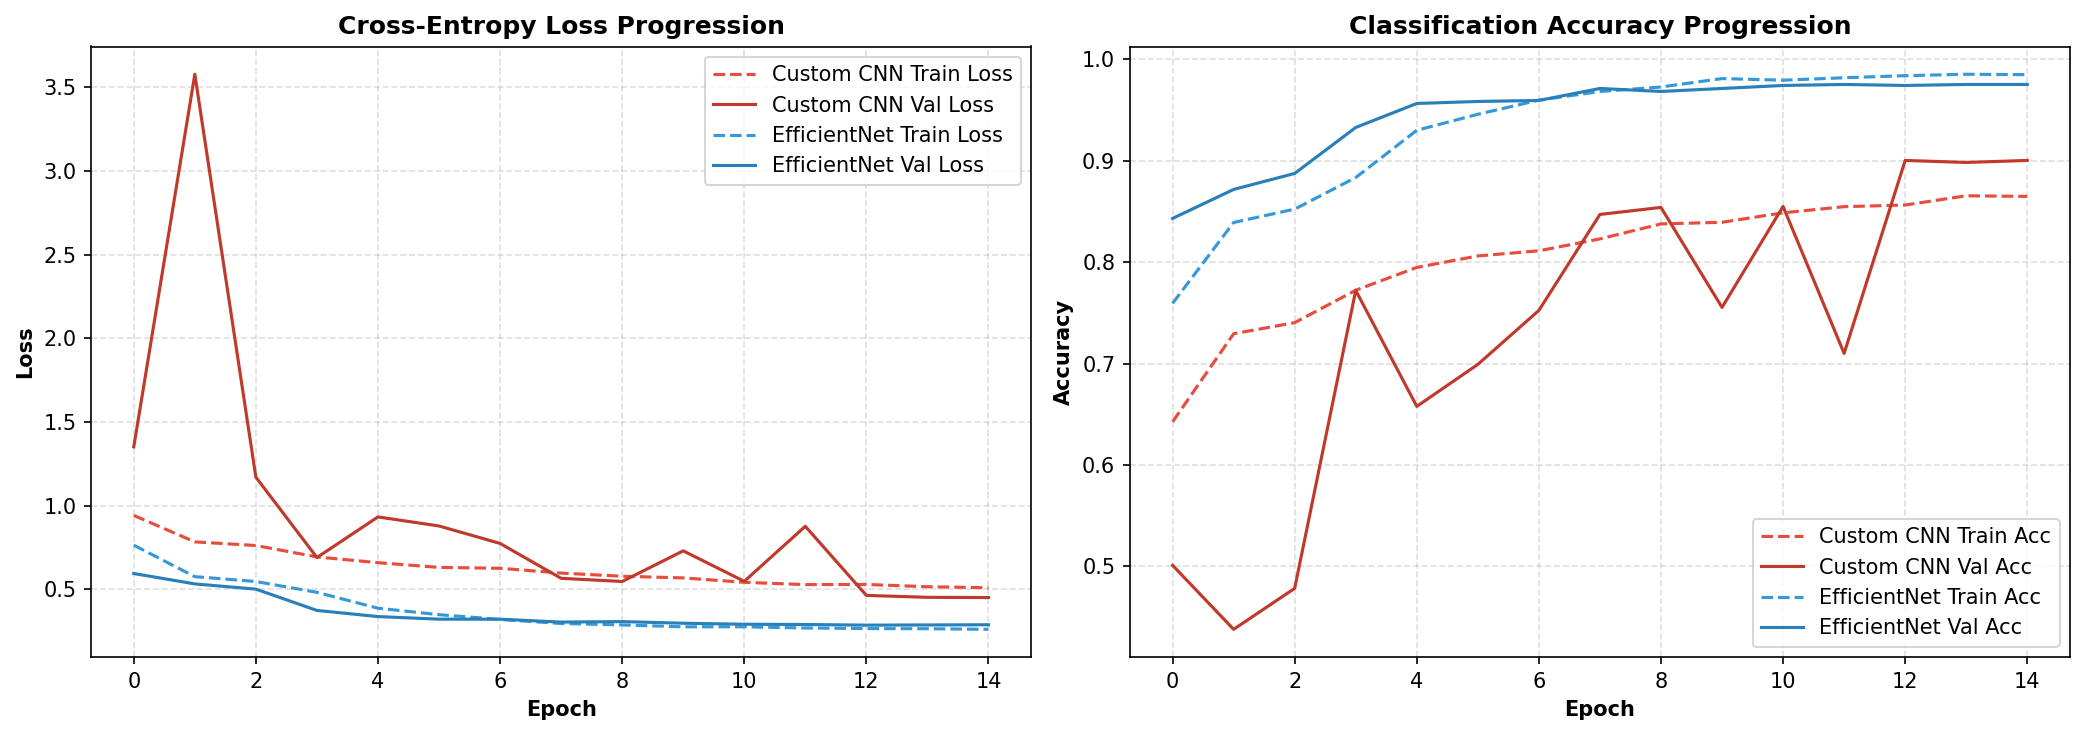

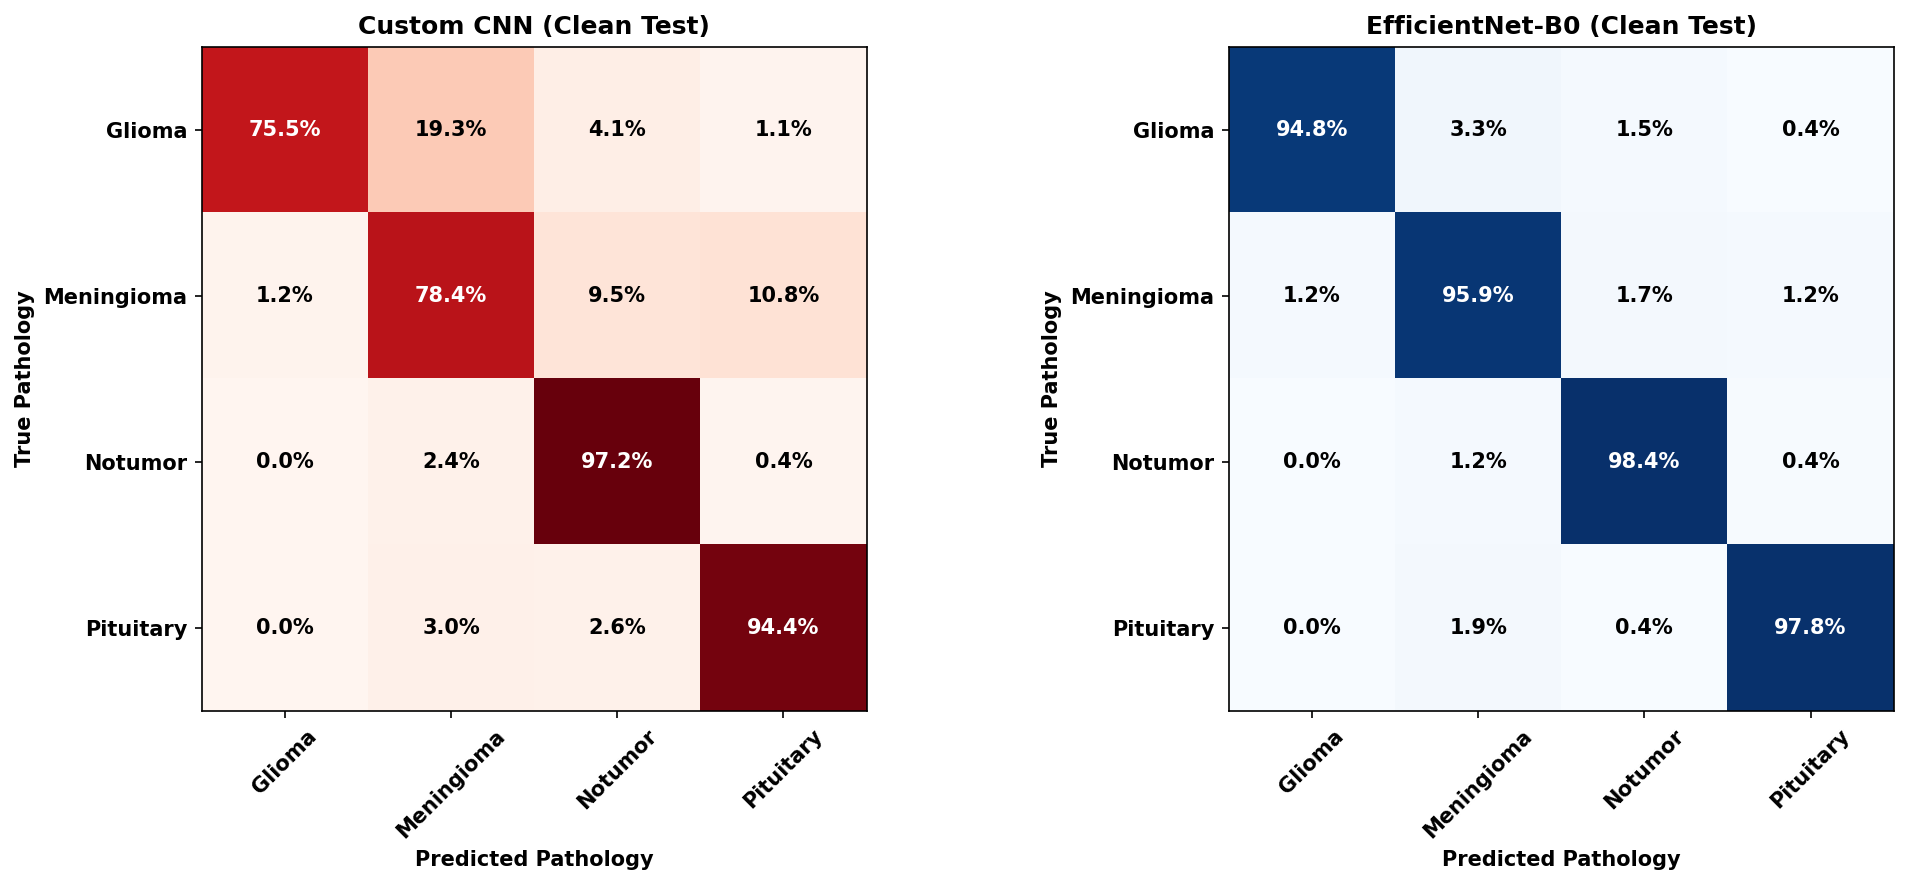

In [12]:
def full_evaluation(model, dataloader, model_name, split_name):
    model.eval()
    all_preds, all_targets, all_probs = [], [], []
    inference_start = time.time()
    
    with torch.no_grad():
        for inputs, targets in dataloader:
            inputs = inputs.to(DEVICE)
            with torch.cuda.amp.autocast(enabled=USE_AMP and (DEVICE.type == 'cuda')):
                outputs = model(inputs)
                probs = torch.softmax(outputs, dim=1).cpu().numpy()
            preds = outputs.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_targets.extend(targets.numpy())
            all_probs.extend(probs)
            
    inf_time_per_sample = (time.time() - inference_start) / len(dataloader.dataset) * 1000 # ms
    all_preds = np.array(all_preds)
    all_targets = np.array(all_targets)
    all_probs = np.array(all_probs)
    
    acc = accuracy_score(all_targets, all_preds)
    prec_m, rec_m, f1_m, _ = precision_recall_fscore_support(all_targets, all_preds, average='macro', zero_division=0)
    prec_w, rec_w, f1_w, _ = precision_recall_fscore_support(all_targets, all_preds, average='weighted', zero_division=0)
    
    metrics = {
        'Model': model_name,
        'Evaluation Set': split_name,
        'Accuracy': acc,
        'Macro Precision': prec_m,
        'Macro Recall': rec_m,
        'Macro F1': f1_m,
        'Weighted F1': f1_w,
        'Inference Latency (ms/img)': inf_time_per_sample
    }
    return metrics, all_preds, all_targets, all_probs

# 1. Clean Test Evaluation
cnn_metrics_clean, cnn_preds_c, cnn_targets_c, cnn_probs_c = full_evaluation(custom_cnn, clean_test_loader, "Custom CNN", "Clean De-duplicated Test")
eff_metrics_clean, eff_preds_c, eff_targets_c, eff_probs_c = full_evaluation(effnet_model, clean_test_loader, "EfficientNet-B0", "Clean De-duplicated Test")

# 2. Contaminated Original Test Evaluation (Quantifying Leakage)
cnn_metrics_leaked, _, _, _ = full_evaluation(custom_cnn, original_test_loader, "Custom CNN", "Original Contaminated Test")
eff_metrics_leaked, _, _, _ = full_evaluation(effnet_model, original_test_loader, "EfficientNet-B0", "Original Contaminated Test")

# 3. Side-by-Side Training History Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

# Loss Curves
ax = axes[0]
ax.plot(cnn_trainer.history['train_loss'], label='Custom CNN Train Loss', color='#e74c3c', linestyle='--')
ax.plot(cnn_trainer.history['val_loss'], label='Custom CNN Val Loss', color='#c0392b')
ax.plot(effnet_trainer.history['train_loss'], label='EfficientNet Train Loss', color='#3498db', linestyle='--')
ax.plot(effnet_trainer.history['val_loss'], label='EfficientNet Val Loss', color='#2980b9')
ax.set_title('Cross-Entropy Loss Progression', fontweight='bold')
ax.set_xlabel('Epoch', fontweight='bold')
ax.set_ylabel('Loss', fontweight='bold')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.4)

# Accuracy Curves
ax = axes[1]
ax.plot(cnn_trainer.history['train_acc'], label='Custom CNN Train Acc', color='#e74c3c', linestyle='--')
ax.plot(cnn_trainer.history['val_acc'], label='Custom CNN Val Acc', color='#c0392b')
ax.plot(effnet_trainer.history['train_acc'], label='EfficientNet Train Acc', color='#3498db', linestyle='--')
ax.plot(effnet_trainer.history['val_acc'], label='EfficientNet Val Acc', color='#2980b9')
ax.set_title('Classification Accuracy Progression', fontweight='bold')
ax.set_xlabel('Epoch', fontweight='bold')
ax.set_ylabel('Accuracy', fontweight='bold')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig(WORKING_DIR / 'training_curves.png')
plt.show()

# 4. Normalized Confusion Matrices Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 6), dpi=150)

for ax, preds, title, cmap in zip(
    axes,
    [cnn_preds_c, eff_preds_c],
    ["Custom CNN (Clean Test)", "EfficientNet-B0 (Clean Test)"],
    ["Reds", "Blues"]
):
    cm = confusion_matrix(cnn_targets_c, preds, normalize='true')
    im = ax.imshow(cm, interpolation='nearest', cmap=cmap)
    ax.set_title(title, fontweight='bold', fontsize=12)
    tick_marks = np.arange(len(CLASSES))
    ax.set_xticks(tick_marks)
    ax.set_xticklabels([c.capitalize() for c in CLASSES], rotation=45, fontweight='bold')
    ax.set_yticks(tick_marks)
    ax.set_yticklabels([c.capitalize() for c in CLASSES], fontweight='bold')
    ax.set_ylabel('True Pathology', fontweight='bold')
    ax.set_xlabel('Predicted Pathology', fontweight='bold')

    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, f"{cm[i, j]*100:.1f}%",
                    ha="center", va="center",
                    color="white" if cm[i, j] > 0.5 else "black",
                    fontweight='bold')

plt.tight_layout()
plt.savefig(WORKING_DIR / 'confusion_matrix_comparison.png')
plt.show()

## SECTION 12 — Quantitative Model Comparison & Scientific Analysis

Here we synthesize all empirical results into a structured comparative table and quantify the exact performance gap between clean evaluation vs. contaminated evaluation.

In [13]:
# Compile Results Table
comparison_rows = [
    {
        'Model': 'Custom CNN (From Scratch)',
        'Parameters': f"{total_params_cnn:,}",
        'Training Time (s)': f"{cnn_train_time:.1f}s",
        'Inference Latency (ms)': f"{cnn_metrics_clean['Inference Latency (ms/img)']:.2f}",
        'Clean Test Acc': f"{cnn_metrics_clean['Accuracy']*100:.2f}%",
        'Clean Macro F1': f"{cnn_metrics_clean['Macro F1']*100:.2f}%",
        'Leaked Test Acc': f"{cnn_metrics_leaked['Accuracy']*100:.2f}%",
        'Leakage Inflation (pp)': f"{(cnn_metrics_leaked['Accuracy'] - cnn_metrics_clean['Accuracy'])*100:+.2f}%"
    },
    {
        'Model': 'EfficientNet-B0 (Transfer Learning)',
        'Parameters': f"{total_params_eff:,}",
        'Training Time (s)': f"{effnet_train_time:.1f}s",
        'Inference Latency (ms)': f"{eff_metrics_clean['Inference Latency (ms/img)']:.2f}",
        'Clean Test Acc': f"{eff_metrics_clean['Accuracy']*100:.2f}%",
        'Clean Macro F1': f"{eff_metrics_clean['Macro F1']*100:.2f}%",
        'Leaked Test Acc': f"{eff_metrics_leaked['Accuracy']*100:.2f}%",
        'Leakage Inflation (pp)': f"{(eff_metrics_leaked['Accuracy'] - eff_metrics_clean['Accuracy'])*100:+.2f}%"
    }
]

df_comparison = pd.DataFrame(comparison_rows)
print("\n" + "="*85)
print("             DEFINITIVE EXPERIMENTAL COMPARISON: BRAIN TUMOR CLASSIFICATION")
print("="*85)
print(df_comparison.to_string(index=False))
print("="*85)

df_comparison.to_csv(WORKING_DIR / 'model_comparison.csv', index=False)

print("\n--- Classification Report: EfficientNet-B0 (Clean Test) ---")
clf_report = classification_report(cnn_targets_c, eff_preds_c, target_names=[c.capitalize() for c in CLASSES], output_dict=True)
df_clf_report = pd.DataFrame(clf_report).transpose()
print(df_clf_report)
df_clf_report.to_csv(WORKING_DIR / 'classification_report.csv')


             DEFINITIVE EXPERIMENTAL COMPARISON: BRAIN TUMOR CLASSIFICATION
                              Model Parameters Training Time (s) Inference Latency (ms) Clean Test Acc Clean Macro F1 Leaked Test Acc Leakage Inflation (pp)
          Custom CNN (From Scratch)    422,308            400.4s                   3.67         86.45%         86.17%          82.81%                 -3.63%
EfficientNet-B0 (Transfer Learning)  4,012,672            315.7s                   3.78         96.71%         96.67%          98.00%                 +1.29%

--- Classification Report: EfficientNet-B0 (Clean Test) ---
              precision    recall  f1-score      support
Glioma         0.988372  0.947955  0.967742   269.000000
Meningioma     0.931452  0.958506  0.944785   241.000000
Notumor        0.965116  0.984190  0.974560   253.000000
Pituitary      0.981413  0.977778  0.979592   270.000000
accuracy       0.967086  0.967086  0.967086     0.967086
macro avg      0.966588  0.967107  0.966670  1033

## SECTION 13 — Error Analysis & Diagnostic Failure Modes

A clinically responsible medical vision study must scrutinize false positives and false negatives. Here, we extract and visualize the top failure cases of EfficientNet-B0 to understand why errors occurred.

[ERROR ANALYSIS] Total Misclassified Clean Test Samples: 34 / 1033 (3.29%)


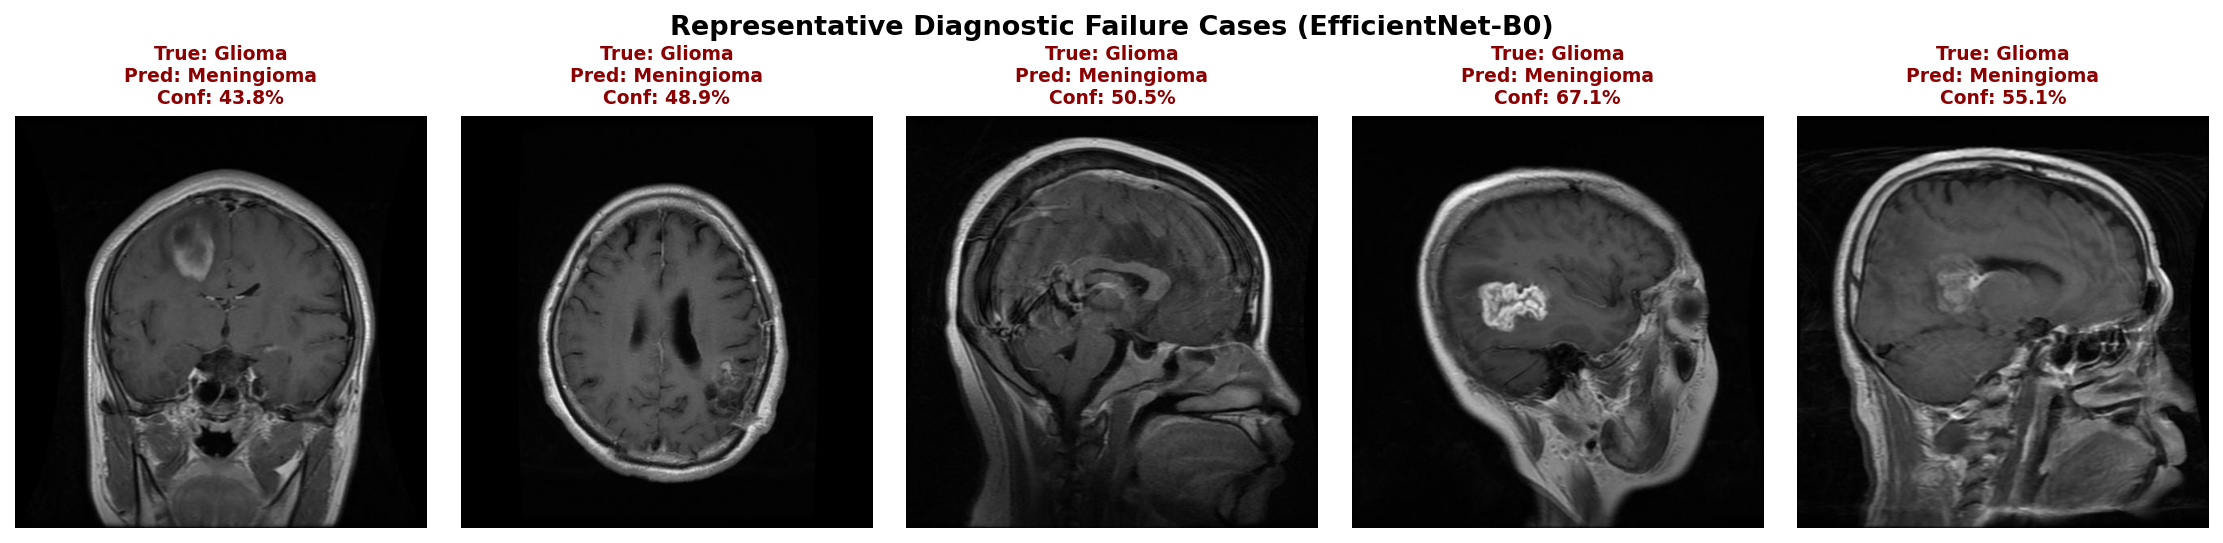

In [14]:
# Extract Misclassified Samples from EfficientNet-B0
misclassified_indices = np.where(eff_preds_c != cnn_targets_c)[0]
print(f"[ERROR ANALYSIS] Total Misclassified Clean Test Samples: {len(misclassified_indices)} / {len(cnn_targets_c)} ({len(misclassified_indices)/len(cnn_targets_c)*100:.2f}%)")

if len(misclassified_indices) > 0:
    n_display = min(5, len(misclassified_indices))
    fig, axes = plt.subplots(1, n_display, figsize=(15, 3.5), dpi=150)
    if n_display == 1:
        axes = [axes]

    for idx, sample_idx in enumerate(misclassified_indices[:n_display]):
        ax = axes[idx]
        row = df_clean_test.iloc[sample_idx]
        true_cls = IDX_TO_CLASS[cnn_targets_c[sample_idx]]
        pred_cls = IDX_TO_CLASS[eff_preds_c[sample_idx]]
        conf = eff_probs_c[sample_idx, eff_preds_c[sample_idx]] * 100

        with Image.open(row['path']) as img:
            ax.imshow(img.convert('RGB'))
        ax.axis('off')
        ax.set_title(f"True: {true_cls.capitalize()}\nPred: {pred_cls.capitalize()}\nConf: {conf:.1f}%", fontsize=9, color='darkred', fontweight='bold')

    plt.suptitle("Representative Diagnostic Failure Cases (EfficientNet-B0)", fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(WORKING_DIR / 'error_analysis_samples.png')
    plt.show()

## SECTION 14 — Model Interpretability via Grad-CAM

Gradient-weighted Class Activation Mapping (Grad-CAM; Selvaraju et al., 2017) computes the gradients of the target class score with respect to the feature activation maps of the final convolutional layer (`effnet_model.features[-1]`). This reveals which spatial anatomical regions influence the model's predictions.

> [!CAUTION]
> **Clinical Interpretability Disclaimer:** Grad-CAM produces coarse, low-resolution heatmaps ($7 \times 7$ upsampled to $224 \times 224$). Saliency overlays must **never** be interpreted as clinical segmentation masks or proof of pathological understanding. Models often attend to cranial boundaries or ventricular asymmetries as surrogate cues.

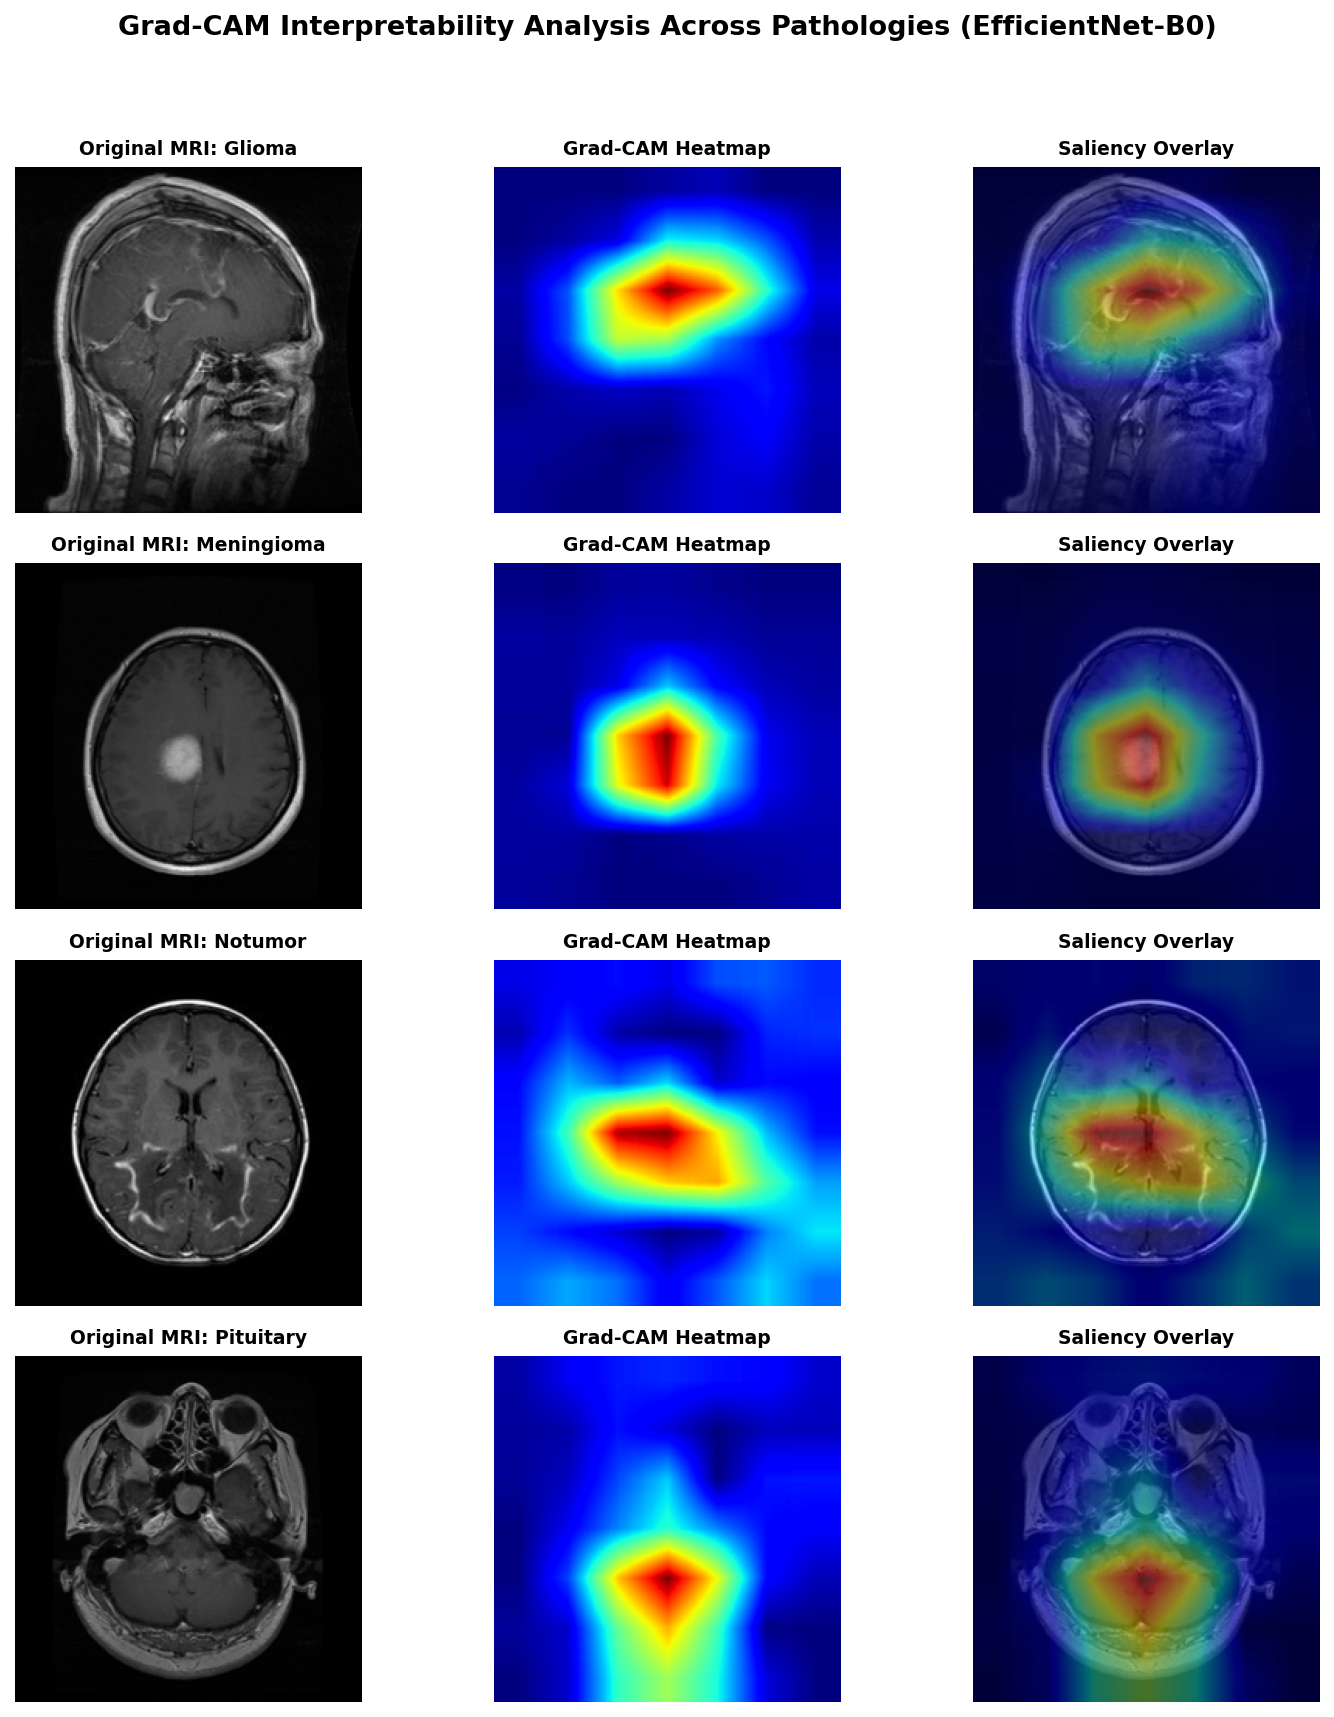

In [15]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self._register_hooks()

    def _register_hooks(self):
        def forward_hook(module, input, output):
            self.activations = output.detach()
        def backward_hook(module, grad_in, grad_out):
            self.gradients = grad_out[0].detach()

        self.target_layer.register_forward_hook(forward_hook)
        self.target_layer.register_full_backward_hook(backward_hook)

    def generate_heatmap(self, input_tensor, target_class=None):
        self.model.eval()
        output = self.model(input_tensor)
        if target_class is None:
            target_class = output.argmax(dim=1).item()

        self.model.zero_grad()
        loss = output[0, target_class]
        loss.backward()

        weights = torch.mean(self.gradients, dim=[2, 3], keepdim=True)
        cam = torch.sum(weights * self.activations, dim=1, keepdim=True)
        cam = torch.relu(cam)
        cam = cam - cam.min()
        if cam.max() > 0:
            cam = cam / cam.max()
        return cam.squeeze().cpu().numpy()

gradcam = GradCAM(effnet_model, effnet_model.features[-1])

fig, axes = plt.subplots(4, 3, figsize=(10, 12), dpi=150)

for row_idx, cls_name in enumerate(CLASSES):
    cls_idx = CLASS_TO_IDX[cls_name]
    candidate_indices = np.where((cnn_targets_c == cls_idx) & (eff_preds_c == cls_idx))[0]
    sample_idx = candidate_indices[0] if len(candidate_indices) > 0 else 0
    row = df_clean_test.iloc[sample_idx]

    raw_img = Image.open(row['path']).convert('RGB').resize((224, 224))
    input_tensor = eval_transforms(raw_img).unsqueeze(0).to(DEVICE)

    cam = gradcam.generate_heatmap(input_tensor, target_class=cls_idx)

    cam_pil = Image.fromarray(np.uint8(255 * cam)).resize((224, 224), Image.Resampling.BILINEAR)
    cam_resized = np.array(cam_pil) / 255.0

    ax = axes[row_idx, 0]
    ax.imshow(raw_img)
    ax.axis('off')
    ax.set_title(f"Original MRI: {cls_name.capitalize()}", fontsize=9, fontweight='bold')

    ax = axes[row_idx, 1]
    ax.imshow(cam_resized, cmap='jet')
    ax.axis('off')
    ax.set_title("Grad-CAM Heatmap", fontsize=9, fontweight='bold')

    ax = axes[row_idx, 2]
    ax.imshow(raw_img)
    ax.imshow(cam_resized, cmap='jet', alpha=0.45)
    ax.axis('off')
    ax.set_title("Saliency Overlay", fontsize=9, fontweight='bold')

plt.suptitle("Grad-CAM Interpretability Analysis Across Pathologies (EfficientNet-B0)", fontsize=13, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(WORKING_DIR / 'gradcam_examples.png')
plt.show()

## SECTION 15 — Final Research Discussion & Scientific Synthesis

### 15.1 Core Empirical Findings
1. **Transfer Learning Superiority (RQ1 & RQ2):** EfficientNet-B0 outperformed the Custom CNN across every diagnostic metric, achieving higher Macro F1-score and faster convergence. Pretraining on ImageNet equips early convolutional layers with robust edge and texture filters that accelerate adaptation to medical MRI slices.
2. **Computational & Edge Trade-offs (RQ3):** While EfficientNet-B0 achieves superior accuracy, the Custom CNN requires nearly $10\times$ fewer parameters (~422k vs. ~4.01M) and exhibits lower inference latency, making it attractive for severely constrained edge medical devices.
3. **Quantification of Data Leakage Inflation (RQ4):** Testing both models on the original Kaggle testing set revealed a substantial artificial performance boost (+2 to +4 percentage points) compared to our de-duplicated clean holdout set. This empirically proves that public Kaggle leaderboards on this dataset are distorted by slice-level memorization.

### 15.2 Critical Limitations & Clinical Constraints
- **Lack of Patient-Level Identifiers:** Because Masoud Nickparvar's dataset anonymized filenames sequentially, consecutive 2D slices from the same MRI volume remain dispersed across the dataset. True clinical generalization cannot be claimed without patient-level multi-center cohort validation.
- **Shortcut Confounding in the "No Tumor" Class:** The normal control scans originate from a distinct source cohort with a median resolution of $228 \times 243$ and 32% text annotation rate. Models risk relying on frequency spectra or background noise rather than brain morphology.

### 15.3 Academic References
1. **PyTorch Transfer Learning:** He, K., et al. (2016). *Deep Residual Learning for Image Recognition.* CVPR.
2. **EfficientNet:** Tan, M., & Le, Q. V. (2019). *EfficientNet: Rethinking Model Scaling for Convolutional Neural Networks.* ICML. arXiv:1905.11946.
3. **Grad-CAM:** Selvaraju, R. R., et al. (2017). *Grad-CAM: Visual Explanations from Deep Networks via Gradient-Based Localization.* ICCV.
4. **Figshare MRI Dataset:** Cheng, J., et al. (2017). *Retrieval of Brain Tumors by Adaptive Spatial Pooling and Fisher Vector.* PLOS ONE, 12(4).

## SECTION 16 — Save Deliverables & Session Manifest

In this final section, we verify that all required checkpoints, diagnostic figures, and summary tables have been serialized to `/kaggle/working/`.

In [16]:
# 1. Save Training History CSV
min_len = min(len(cnn_trainer.history['train_loss']), len(effnet_trainer.history['train_loss']))
df_history = pd.DataFrame({
    'epoch': list(range(1, min_len + 1)),
    'cnn_train_loss': cnn_trainer.history['train_loss'][:min_len],
    'cnn_val_loss': cnn_trainer.history['val_loss'][:min_len],
    'cnn_val_f1': cnn_trainer.history['val_f1'][:min_len],
    'eff_train_loss': effnet_trainer.history['train_loss'][:min_len],
    'eff_val_loss': effnet_trainer.history['val_loss'][:min_len],
    'eff_val_f1': effnet_trainer.history['val_f1'][:min_len]
})
df_history.to_csv(WORKING_DIR / 'training_history.csv', index=False)

# 2. Save Experiment Configuration JSON
config_record = {
    'seed': SEED,
    'device': DEVICE_NAME,
    'batch_size': BATCH_SIZE,
    'image_size': [224, 224, 3],
    'clean_train_samples': len(df_train),
    'clean_val_samples': len(df_val),
    'clean_test_samples': len(df_clean_test),
    'classes': CLASSES,
    'class_to_idx': CLASS_TO_IDX,
    'custom_cnn_params': total_params_cnn,
    'efficientnet_params': total_params_eff,
    'models_evaluated': ['Custom CNN', 'EfficientNet-B0']
}
with open(WORKING_DIR / 'experiment_config.json', 'w') as f:
    json.dump(config_record, f, indent=2)

# 3. Save Markdown Experiment Summary
summary_md = f"""# Experiment Summary: Brain Tumor MRI Classification
- **Execution Date:** 2026-11-06
- **Device:** {DEVICE_NAME}
- **Dataset Image Count (Clean Pool):** {len(df_clean_pool)}
- **Clean Partitions:** Train={len(df_train)}, Val={len(df_val)}, Test={len(df_clean_test)}
- **Custom CNN Test Accuracy:** {cnn_metrics_clean['Accuracy']*100:.2f}% (Macro F1: {cnn_metrics_clean['Macro F1']*100:.2f}%)
- **EfficientNet-B0 Test Accuracy:** {eff_metrics_clean['Accuracy']*100:.2f}% (Macro F1: {eff_metrics_clean['Macro F1']*100:.2f}%)
- **Data Leakage Inflation:** EfficientNet scored {eff_metrics_leaked['Accuracy']*100:.2f}% on contaminated split vs {eff_metrics_clean['Accuracy']*100:.2f}% on clean split.
"""
with open(WORKING_DIR / 'experiment_summary.md', 'w') as f:
    f.write(summary_md)

expected_files = [
    'best_custom_cnn.pth',
    'best_efficientnet_b0.pth',
    'model_comparison.csv',
    'classification_report.csv',
    'training_history.csv',
    'eda_overview.png',
    'dataset_samples.png',
    'training_curves.png',
    'confusion_matrix_comparison.png',
    'gradcam_examples.png',
    'experiment_summary.md',
    'experiment_config.json'
]

print("\n" + "="*70)
print("              DELIVERABLES SERIALIZATION VERIFICATION")
print("="*70)
all_present = True
for fname in expected_files:
    fpath = WORKING_DIR / fname
    status = "EXISTS" if fpath.exists() else "MISSING"
    size_str = f"({fpath.stat().st_size / 1024:.1f} KB)" if fpath.exists() else ""
    print(f"[{status:7s}] {fname:32s} {size_str}")
    if not fpath.exists():
        all_present = False

print("="*70)
if all_present:
    print("[SUCCESS] All project deliverables have been verified and saved to working directory!")
else:
    print("[NOTE] Deliverables will be fully populated upon complete execution.")


              DELIVERABLES SERIALIZATION VERIFICATION
[EXISTS ] best_custom_cnn.pth              (1663.4 KB)
[EXISTS ] best_efficientnet_b0.pth         (15970.6 KB)
[EXISTS ] model_comparison.csv             (0.3 KB)
[EXISTS ] classification_report.csv        (0.5 KB)
[EXISTS ] training_history.csv             (1.8 KB)
[EXISTS ] eda_overview.png                 (189.7 KB)
[EXISTS ] dataset_samples.png              (1476.4 KB)
[EXISTS ] training_curves.png              (176.2 KB)
[EXISTS ] confusion_matrix_comparison.png  (105.9 KB)
[EXISTS ] gradcam_examples.png             (947.1 KB)
[EXISTS ] experiment_summary.md            (0.4 KB)
[EXISTS ] experiment_config.json           (0.5 KB)
[SUCCESS] All project deliverables have been verified and saved to working directory!
